# Mask 更新測試 (3D 版)

把自訂的 n×n boolean mask（`False` = base color、`True` = highlight）轉成逐髮絲 (per-strand) mask，
再依髮絲的 3D 幾何更新 mask，最後存成 `coloring_by_strand` 的 per-strand template 交給 Blender 渲染。

演算法與工具都已整理成 library，這本 notebook 只負責呼叫與看結果：

| library | 內容 |
|---|---|
| [`update_contour`](../update_contour/README.md) | `ScalpGrid`（頭皮 grid / 切線基底 / 髮絲歸屬）、mask 轉換、3D 通量、majority vote、FM、3D active contour、trim |
| [`mask_analysis`](../mask_analysis/README.md) | 分析數值 (`scores`)、畫圖 (`plots`)、Blender 渲染 (`render`) |

邊緣訊號是每格 3D 柱體的**淨向外通量** ∮ v·n̂ dA（`update_contour.cal_grid_flux_3d`）：直接在 3D 局部座標
(t1, t2, normal) 上量髮絲單位流向的法向分量，不擬合、不求導；只有畫圖時才把流向投影到 2D。

In [28]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

HERE = "/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample"
PROJECT_ROOT = os.path.abspath(os.path.join(HERE, "..", "..", ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import highlighting.generate_from_3D_models.update_contour as uc
import highlighting.generate_from_3D_models.mask_analysis as ma
from highlighting.generate_from_3D_models.mask_analysis import plots, render
from highlighting.generate_from_3D_models.scalp_grid_volume_sample.hair_query import load_strands

plots.setup_cjk_font()

DATASET_ROOT = uc.default_dataset_path()   # <PROJECT_ROOT>/DiffLocks_Dataset/difflocks_dataset
# testdata_name = "base_13_idx_94847"
# testdata_name = 'base_67_idx_77057'
# testdata_name = 'base_69_idx_1563'
testdata_name = 'base_30_idx_94033'


HAIRSTYLE_DIR = os.path.join(DATASET_ROOT, "generated_hairstyles", testdata_name)
STRANDS_NPZ = os.path.join(HAIRSTYLE_DIR, "full_strands.npz")
N = 32  # grid 解析度 (N x N)

## 1. 頭皮 grid 與髮絲

`ScalpGrid.from_dataset(N)` 一次建好：每格的 3D 位置 / 法向量、切線基底 (t1: +u, t2: +v)、柱體半寬 `half_size`、UV bin。
`strand_mask_grid[u, v, k]` = 第 k 根髮絲是否穿過格子 (u, v) 上方的柱體（有 CUDA 就走 GPU）。

索引慣例：`grid.*` / `strand_mask_grid` 是 `(u_idx, v_idx)` 排列；所有 N×N mask / 分數圖是 `(row, col)` 排列
（row 0 = 高 v 端，跟 template PNG 一致），`uc.uv_to_rc` 負責轉換。

有效 (落在頭皮上) 的 cell 數: 730 / 1024, half_size = 0.00599
strand_positions: (99450, 256, 3)


100%|██████████| 46/46 [00:06<00:00,  6.73it/s]


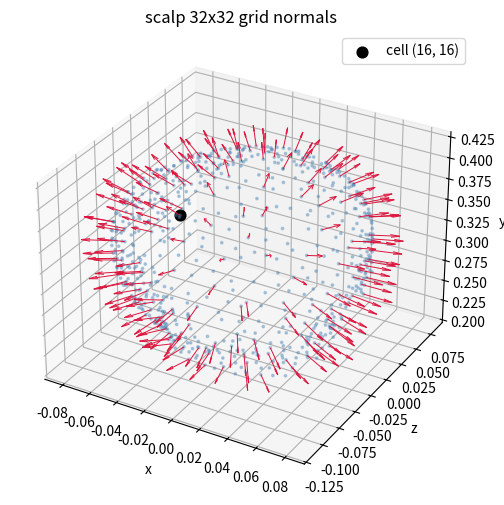

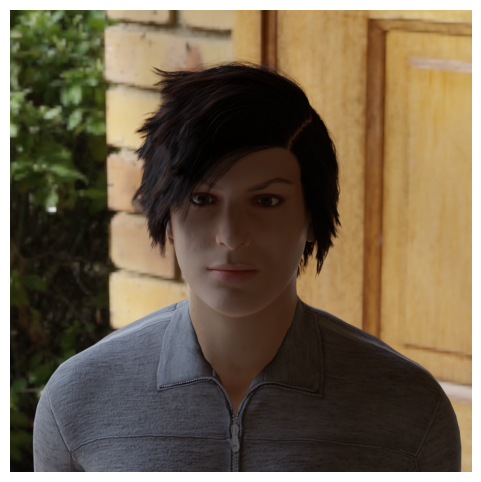

In [29]:
grid = uc.ScalpGrid.from_dataset(N)
g = grid.arrays()   # grid_pos, grid_normal, grid_valid, half_size, grid_t1, grid_t2
print(f"有效 (落在頭皮上) 的 cell 數: {grid.grid_valid.sum()} / {grid.grid_valid.size}, half_size = {grid.half_size:.5f}")

strand_positions, root_uv, root_normal = load_strands(STRANDS_NPZ)
print("strand_positions:", strand_positions.shape)   # (S, P, 3)

row_idx, col_idx = grid.root_rowcol(root_uv)           # 每根髮絲髮根所在的 (row, col)
strands_mask_grid = grid.strand_mask_grid(strand_positions)   # (N, N, S) bool

plots.plot_grid_normals_3d(g["grid_pos"], g["grid_normal"], g["grid_valid"], cell=(N // 2, N // 2))
plt.figure(figsize=(6, 6)); plt.imshow(plt.imread(os.path.join(HAIRSTYLE_DIR, "rgb.png"))); plt.axis("off");

## 2. 自訂 N×N mask -> 逐髮絲 mask

每根髮絲的 mask = 它髮根所在格子的值（`grid_mask_to_strand_mask`）。

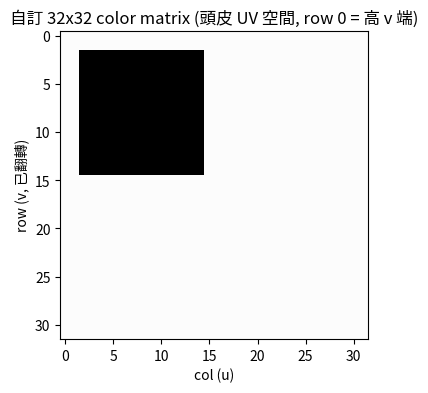

highlight 髮絲數: 20012 / 99450


In [30]:
BASE_COLOR = np.array([0.99, 0.99, 0.99])
HIGHLIGHT_COLOR = np.array([0.0, 0.0, 0.0])

mask_matrix = np.zeros((N, N), dtype=bool)
mask_matrix[2:15, 2:15] = True

plots.show_color_matrix(uc.mask_to_rgb(mask_matrix, BASE_COLOR, HIGHLIGHT_COLOR))
base_strand_mask = uc.grid_mask_to_strand_mask(mask_matrix, row_idx, col_idx)   # (S,) bool
print("highlight 髮絲數:", int(base_strand_mask.sum()), "/", base_strand_mask.size)

100%|██████████| 1024/1024 [00:03<00:00, 267.03it/s]


average |flux| = 0.04833591
edge cells = 34 / 730 valid cells


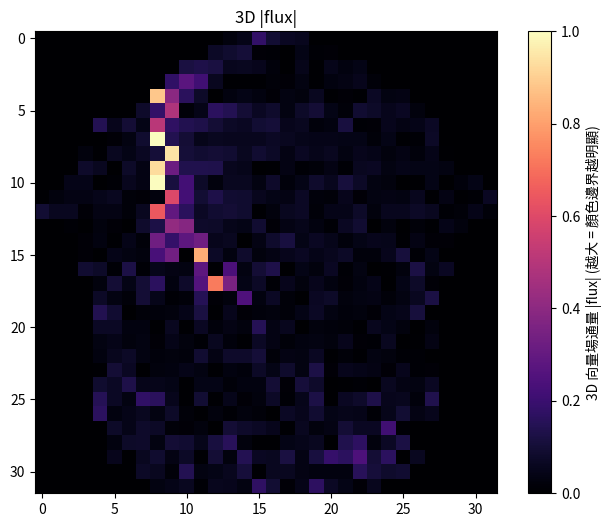

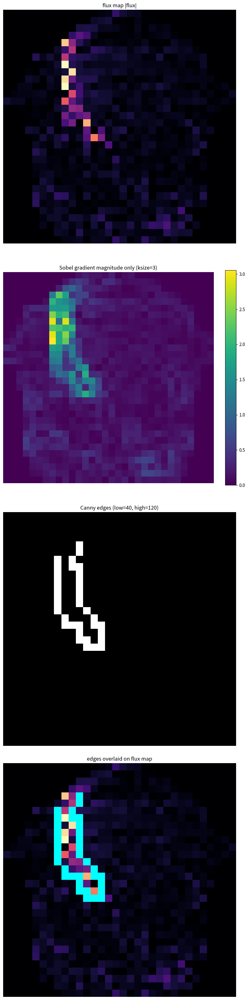

In [31]:
flux3d, flux_ok = uc.cal_grid_flux_3d(
    strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], g["half_size"], strands_mask_grid,
    grid_t1=g["grid_t1"], grid_t2=g["grid_t2"],
)
grid_score = ma.edge_score_from_flux(flux3d)
print("average |flux| =", grid_score.mean())

plots.plot_score_map(grid_score, title="3D |flux|")
edge_result = ma.detect_flux_edges(grid_score, g["grid_valid"], canny_low=40, canny_high=120)
print(f"edge cells = {edge_result['edges'].sum()} / {edge_result['valid_rc'].sum()} valid cells")
plots.plot_flux_edges(grid_score, edge_result, title_suffix=" (low=40, high=120)");

100%|██████████| 1024/1024 [00:03<00:00, 310.18it/s]


strand_pts2d: (26981308, 2)


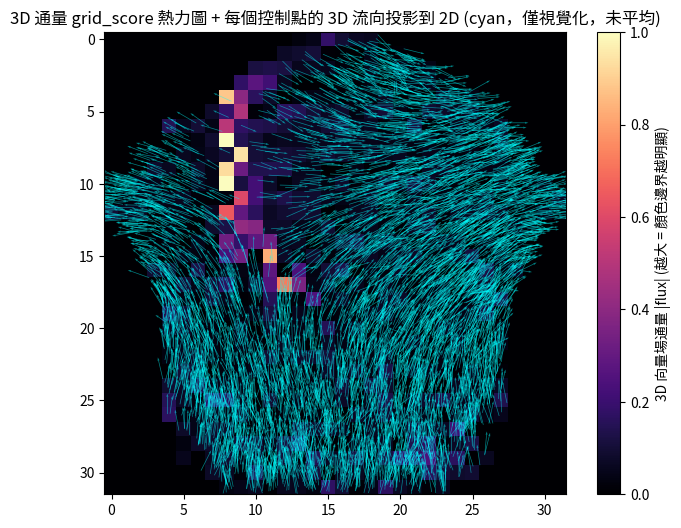

In [32]:
# 每根髮絲每個控制點的 3D 流向投影到 2D (僅視覺化，未平均)
strand_pts2d, strand_vec2d = ma.compute_strand_vectors_2d(
    strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], g["half_size"], strands_mask_grid,
    grid_t1=g["grid_t1"], grid_t2=g["grid_t2"],
)
print("strand_pts2d:", strand_pts2d.shape)
plots.plot_score_with_flow(grid_score, strand_pts2d, strand_vec2d, max_arrows=6000);

## 4. 更新 mask

預設用 FM (Fiduccia-Mattheyses, clique 目標)；`iter_strand_masks[0]` 是初始 mask，之後每個元素是一個 pass 的結果。
另一種做法 (majority vote，原 `update_color`) 放在註解裡。

`OVERLAP` 切換兩根髮絲「重疊」的判定方式：

| `OVERLAP` | 判定 | FM 的輸入 / 目標 |
|---|---|---|
| `"cell"` | 同一格柱體內的髮絲**全部**互相重疊 | `build_cell_incidence`；clique：Σ_c n_true·n_false |
| `"projection"` | 兩根髮絲在該格切平面 (t1, t2) 上的 **2D 投影有相交**才算重疊 | `build_projection_graph` → `StrandGraph`（邊權重 = 相交的格數）；最小化被切開的邊權重，`mode` 被忽略 |

投影判定的圖比同格判定稀疏很多（每根髮絲的加權度數約少 8 倍），所以 `lam` 要跟著調小：
`LAM["cell"] = 10000` 跟 `LAM["projection"] = 1000` 的翻轉比例差不多（base_13_idx_94847：8.7% / 12%）；
`projection` 用 10000 幾乎一根都不會翻。

In [41]:
import time

OVERLAP = "projection"   # "cell" = 同格即重疊 | "projection" = 2D 投影相交才重疊
LAM = {"cell": 10000, "projection": 100}
lam = LAM[OVERLAP]

cell_incidence = uc.build_cell_incidence(strands_mask_grid)
print("cells (>=2 strands):", cell_incidence[0].shape[0] - 1, " incidence nnz:", cell_incidence[1].shape[0])

# 投影相交圖 (只算一次，FM 每個 pass 都重用；第 4b 節的比較也會用到)
t0 = time.time()
proj_graph = uc.build_projection_graph(
    strand_positions, strands_mask_grid, g["grid_pos"], g["grid_normal"], g["half_size"],
    grid_t1=g["grid_t1"], grid_t2=g["grid_t2"],
)
n_clique_pairs = int((np.diff(cell_incidence[0]) * (np.diff(cell_incidence[0]) - 1) // 2).sum())
print(f"projection graph: {proj_graph.n_edges:,} 對髮絲投影相交 ({time.time() - t0:.1f} s)；"
      f"同格判定的 (格, 髮絲對) 數 = {n_clique_pairs:,}")

incidence = proj_graph if OVERLAP == "projection" else cell_incidence
iter_strand_masks = uc.fm_refine(incidence, base_strand_mask, mode="clique", lam=lam, max_passes=3, return_history=True)

# majority vote 版本:
# iter_strand_masks = [base_strand_mask]
# for _ in range(3):
#     iter_strand_masks.append(uc.update_contour_mask(
#         strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], iter_strand_masks[-1], g["half_size"],
#         strands_mask_grid, threshold=0.1, grid_t1=g["grid_t1"], grid_t2=g["grid_t2"]))

n_iter = len(iter_strand_masks) - 1
print("每輪被翻轉的髮絲比例:", ma.mask_change_ratios(iter_strand_masks))

cells (>=2 strands): 722  incidence nnz: 899887


projection overlap: 100%|██████████| 722/722 [00:02<00:00, 310.85it/s]


projection graph: 41,530,487 對髮絲投影相交 (3.4 s)；同格判定的 (格, 髮絲對) 數 = 665,834,140
[FM/graph] start: cut pairs = 7196309, cut weight = 10393688, lam = 100
[FM/graph] pass 0: gain = 7820207, cut pairs = 954047, cut weight = 1347181, diff from state0 = 0.1233
[FM/graph] pass 1: gain = 668674, cut pairs = 472903, cut weight = 655607, diff from state0 = 0.1256
[FM/graph] pass 2: gain = 35399, cut pairs = 442178, cut weight = 612608, diff from state0 = 0.1264
每輪被翻轉的髮絲比例: [0.12330819507290096, 0.036872800402212164, 0.0009854198089492207]


## 4b. 投影相交判定的檢查與比較

1. **單格檢查**：挑一格混色最嚴重的柱體，畫出每根髮絲在該格切平面上的 2D 投影（顏色 = 初始 mask），
   比較「同格判定」的髮絲對數跟「投影相交」的髮絲對數。
2. **兩種判定互相評分**：兩種 `OVERLAP` 各跑一次 FM，最後結果分別用兩種目標函數計分，
   並比較兩個結果的差異。

cell (u, v) = (25, 13): 2425 根髮絲 (highlight 1311, base 1114)
  同格判定: 2,939,100 對重疊, 其中異色 1,460,454 對
  投影相交: 364,592 對重疊, 其中異色 189,303 對
  圖中 40 根: 同格判定 400 對異色重疊, 投影相交 70 對異色重疊


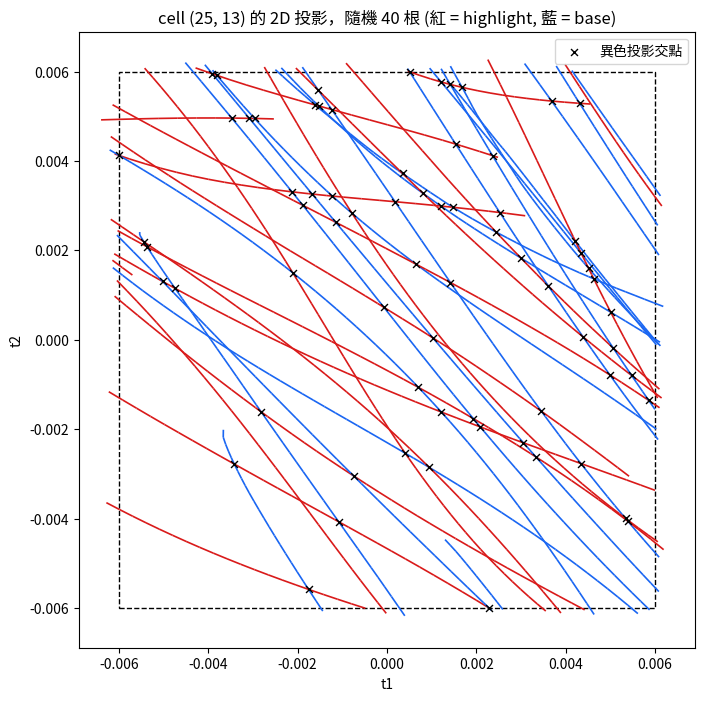

In [42]:
from matplotlib.collections import LineCollection
from highlighting.generate_from_3D_models.update_contour.overlap import cell_frame, crossing_keys, project_segments

# 混色最嚴重的格子: min(highlight 數, base 數) 最大
n_true_cell = (strands_mask_grid & base_strand_mask).sum(axis=-1)
n_false_cell = (strands_mask_grid & ~base_strand_mask).sum(axis=-1)
cu, cv = np.unravel_index(np.argmax(np.minimum(n_true_cell, n_false_cell)), n_true_cell.shape)

members = np.flatnonzero(strands_mask_grid[cu, cv]).astype(np.int64)
segs = project_segments(strand_positions, members, members,
                        *cell_frame(g["grid_pos"], g["grid_t1"], g["grid_t2"], g["grid_normal"], cu, cv),
                        g["half_size"], uc.H_MIN, uc.H_MAX)
S = strand_positions.shape[0]
keys = crossing_keys(*segs[:5], g["half_size"], 0, S, -1)
ka, kb = keys // S, keys % S
opposite = base_strand_mask[ka] != base_strand_mask[kb]
K = members.size
print(f"cell (u, v) = ({cu}, {cv}): {K} 根髮絲 (highlight {n_true_cell[cu, cv]}, base {n_false_cell[cu, cv]})")
print(f"  同格判定: {K * (K - 1) // 2:,} 對重疊, 其中異色 {int(n_true_cell[cu, cv]) * int(n_false_cell[cu, cv]):,} 對")
print(f"  投影相交: {keys.size:,} 對重疊, 其中異色 {int(opposite.sum()):,} 對")

# 圖: 隨機挑 N_SHOW 根 (兩色各半) 畫投影折線，x = 異色髮絲投影的交點
N_SHOW = 40
rng = np.random.default_rng(0)
shown = np.concatenate([rng.choice(members[base_strand_mask[members] == lab], N_SHOW // 2, replace=False)
                        for lab in (True, False)])
sx, sy, ex, ey, owner = segs[:5]
sel = np.isin(owner, shown)
p0, p1, own = np.stack([sx, sy], 1)[sel], np.stack([ex, ey], 1)[sel], owner[sel]
hi = base_strand_mask[own]
A0, A1, B0, B1 = p0[hi], p1[hi], p0[~hi], p1[~hi]
d_a, d_b = (A1 - A0)[:, None], (B1 - B0)[None]
den = d_a[..., 0] * d_b[..., 1] - d_a[..., 1] * d_b[..., 0]
diff = B0[None] - A0[:, None]
with np.errstate(divide="ignore", invalid="ignore"):
    t = (diff[..., 0] * d_b[..., 1] - diff[..., 1] * d_b[..., 0]) / den
    u = (diff[..., 0] * d_a[..., 1] - diff[..., 1] * d_a[..., 0]) / den
ia, ib = np.nonzero((t > 0) & (t < 1) & (u > 0) & (u < 1))
cross_pts = A0[ia] + t[ia, ib, None] * (A1 - A0)[ia]
n_pairs_shown = len(set(zip(own[hi][ia].tolist(), own[~hi][ib].tolist())))
print(f"  圖中 {N_SHOW} 根: 同格判定 {(N_SHOW // 2) ** 2} 對異色重疊, 投影相交 {n_pairs_shown} 對異色重疊")

hs = g["half_size"]
fig, ax = plt.subplots(figsize=(8, 8))
ax.add_collection(LineCollection(np.stack([p0, p1], 1), colors=np.where(hi[:, None], [[0.85, 0.1, 0.1]], [[0.1, 0.4, 0.95]]),
                                 linewidths=1.2))
ax.scatter(cross_pts[:, 0], cross_pts[:, 1], marker="x", c="k", s=25, lw=1, zorder=3, label="異色投影交點")
ax.add_patch(plt.Rectangle((-hs, -hs), 2 * hs, 2 * hs, fill=False, ls="--", color="k"))
ax.set_xlim(-1.15 * hs, 1.15 * hs); ax.set_ylim(-1.15 * hs, 1.15 * hs); ax.set_aspect("equal")
ax.set_xlabel("t1"); ax.set_ylabel("t2"); ax.legend(loc="upper right")
ax.set_title(f"cell ({cu}, {cv}) 的 2D 投影，隨機 {N_SHOW} 根 (紅 = highlight, 藍 = base)");


In [43]:
COMPARE_OVERLAP = False   # 另一種判定也跑一次 FM (多花一次 FM 的時間)

if COMPARE_OVERLAP:
    other = "cell" if OVERLAP == "projection" else "projection"
    runs = {OVERLAP: iter_strand_masks}
    runs[other] = uc.fm_refine(proj_graph if other == "projection" else cell_incidence, base_strand_mask,
                               mode="clique", lam=LAM[other], max_passes=3, return_history=True, verbose=False)

    rows = [("initial", base_strand_mask)] + [(f"FM / {k} (lam={LAM[k]})", v[-1]) for k, v in runs.items()]
    print(f"{'':28s} {'同格: 混色格數':>14s} {'同格: clique cut':>18s} {'投影: 相交異色對':>16s} {'投影: 加權':>12s} {'翻轉比例':>8s}")
    for name, m in rows:
        mixed, cut = uc.fm_objectives(cell_incidence, m)
        pairs, weight = uc.fm_objectives(proj_graph, m)
        print(f"{name:28s} {mixed:14,d} {cut:18,d} {pairs:16,d} {weight:12,d} {(m != base_strand_mask).mean():8.4f}")
    a, b = runs["cell"][-1], runs["projection"][-1]
    print(f"兩種判定的最終結果有 {(a != b).mean():.2%} 的髮絲標籤不同")

    fig, axes = plt.subplots(1, 3, figsize=(21, 7))
    for ax, (name, m) in zip(axes, rows):
        ax.set_facecolor("gray")
        ax.imshow(uc.mask_to_rgb(uc.strand_mask_to_grid_mask(m, strands_mask_grid), BASE_COLOR, HIGHLIGHT_COLOR))
        ax.set_title(name)
    plt.tight_layout()
    plots.plot_strand_uv_iterations(root_uv, [m for _, m in rows], BASE_COLOR, HIGHLIGHT_COLOR,
                                    titles=[name for name, _ in rows]);

## 5. 結果分析

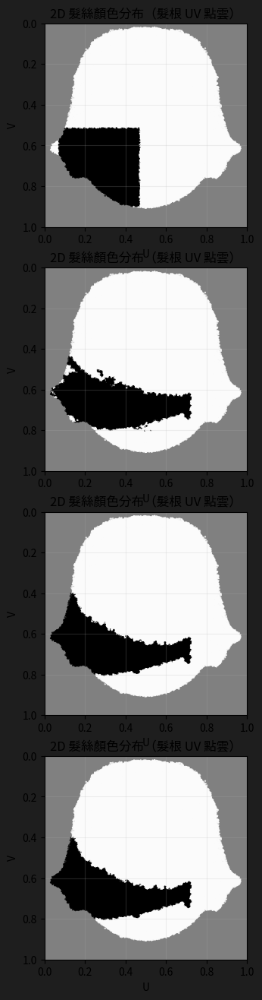

In [44]:
# 髮根 UV 點雲，顏色 = 每輪的 strand mask
plots.plot_strand_uv_iterations(root_uv, iter_strand_masks, BASE_COLOR, HIGHLIGHT_COLOR);


`trim`：每輪挑出跟鄰居衝突最嚴重的 `max_cut` 根髮絲，渲染 `*_trimmed` 版本時整根不畫。

In [45]:
# incidence 是 OVERLAP 選的判定: "projection" 時衝突 = 投影相交的異色髮絲 (邊權重加總)
trimmed_masks = [uc.trim(m, incidence, max_cut=100) for m in iter_strand_masks]

100%|██████████| 1024/1024 [00:02<00:00, 489.29it/s]


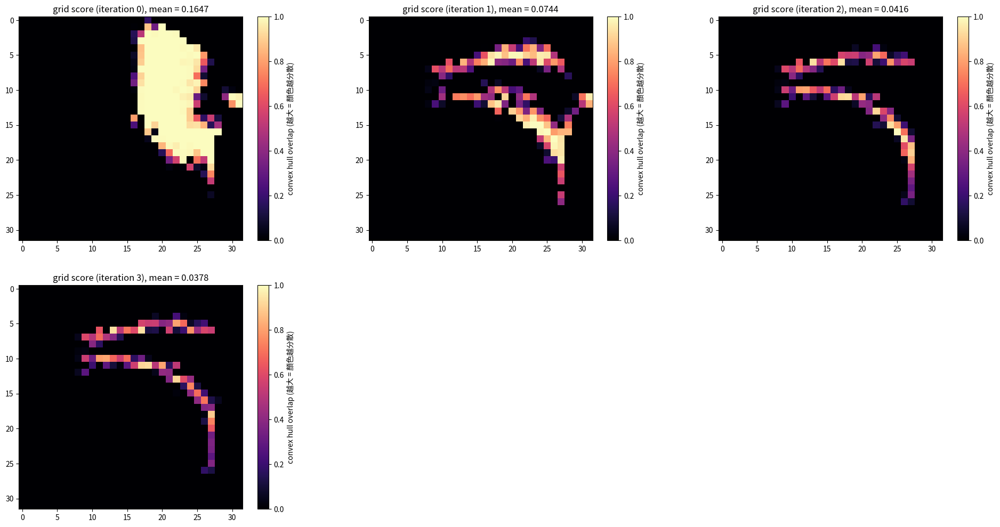

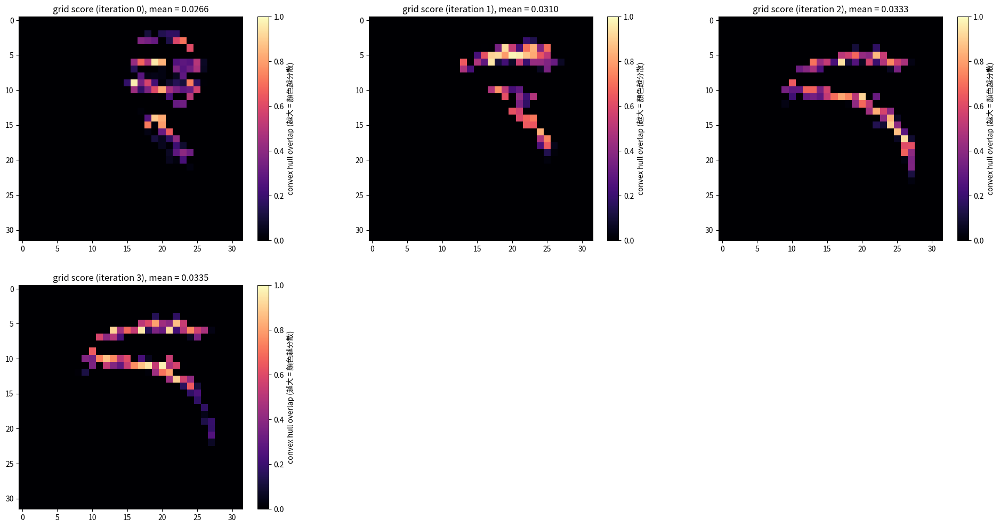

In [46]:
# 每格 convex hull overlap (越大 = 兩種顏色越混)
grid_scores = [
    ma.cal_grid_score(strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], m, g["half_size"],
                      strands_mask_grid, grid_t1=g["grid_t1"], grid_t2=g["grid_t2"])
    for m in iter_strand_masks
]
plots.plot_grid_score_iterations(grid_scores);


# 每格 convex hull overlap (越大 = 兩種顏色越混)
trimmed_grid_scores = [
    ma.cal_grid_score(strand_positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], m, g["half_size"],
                      strands_mask_grid, grid_t1=g["grid_t1"], grid_t2=g["grid_t2"])
    for m in trimmed_masks
]
plots.plot_grid_score_iterations(trimmed_grid_scores);

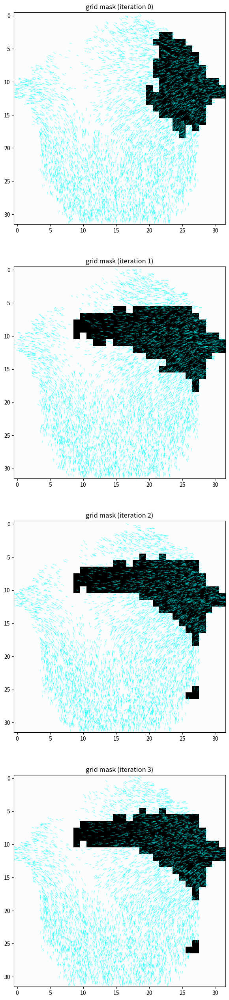

In [47]:
# 每格的 mask 眾數 (2D 結果)，疊上髮絲流向；edge_score=grid_score 可再疊通量點
show_direction_vec = True
show_edge_detect_score = False

grid_masks = [uc.strand_mask_to_grid_mask(m, strands_mask_grid) for m in iter_strand_masks]
plots.plot_grid_mask_iterations(
    grid_masks, BASE_COLOR, HIGHLIGHT_COLOR,
    pts2d=strand_pts2d if show_direction_vec else None,
    vec2d=strand_vec2d if show_direction_vec else None,
    edge_score=grid_score if show_edge_detect_score else None,
);

## 7.Blender 渲染

`render.render_iterations` 把 `iter_strand_masks[0]` 存到 `output/base_3D`、第 i 輪存到 `output/iter_3D_<i>`
（外加 `iter_3D_<i>_trimmed`；`OVERLAP="projection"` 時改成 `iter_3D_projection_<i>`），template 寫到 `coloring_by_strand/{base,median}_templates_3D`。

wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/base_templates_3D/template_notebook_color_matrix.npz
執行 Blender multi-view 渲染...
00:00.293  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.134  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/front.png'
00:26.294  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/_multiview_tmp.png'
00:36.918  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/_multiview_tmp.png'
00:48.345  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/_multiview_tmp.png'
00:59.140  rende

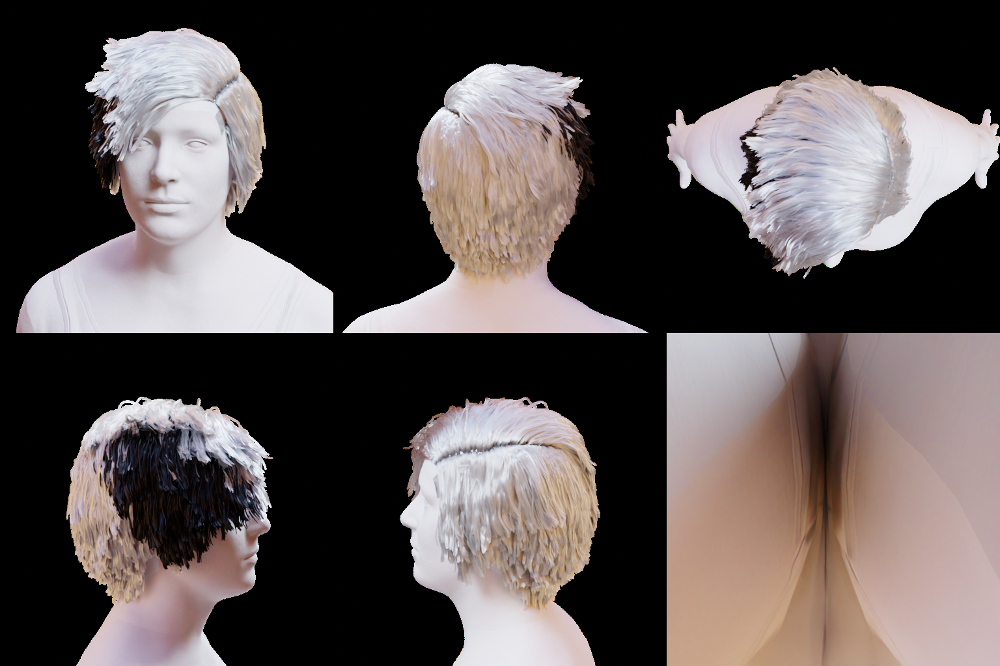

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/base_3D/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
執行 Blender multi-view 渲染...
00:00.262  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.046  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1/front.png'
00:26.264  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1/_multiview_tmp.png'
00:36.887  render           | Saved: '/home/kyh/Desktop/P76154862/high

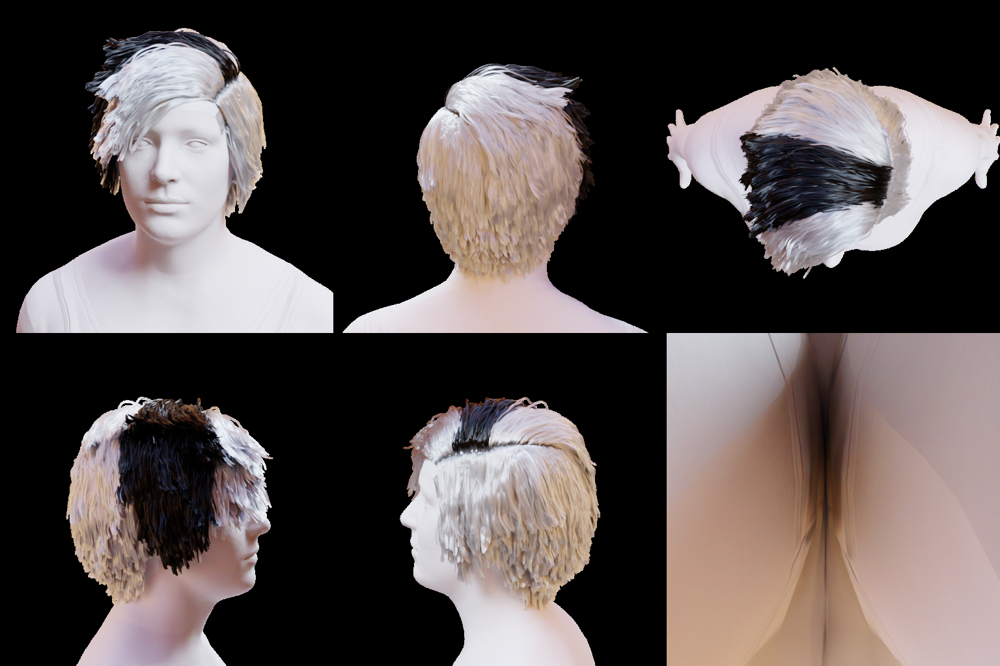

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
wrote ignore mask (100/99450 strands ignored) to /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1_trimmed/ignore_mask.npz
執行 Blender multi-view 渲染 (trimmed)...
00:00.338  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.508  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1_trimmed/front.png'
00:26.795  

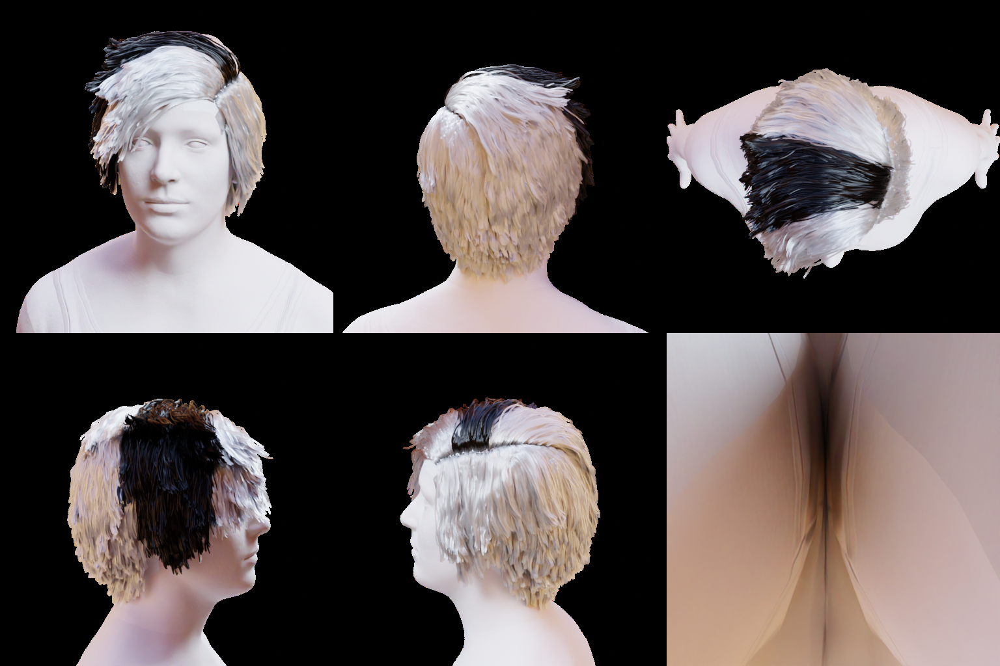

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1_trimmed/ignore_mask.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1_trimmed/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_1_trimmed/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
執行 Blender multi-view 渲染...
00:00.260  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.078  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2/front.png'
00:26.458  render           | Saved: '/home/kyh/Desktop/P76154

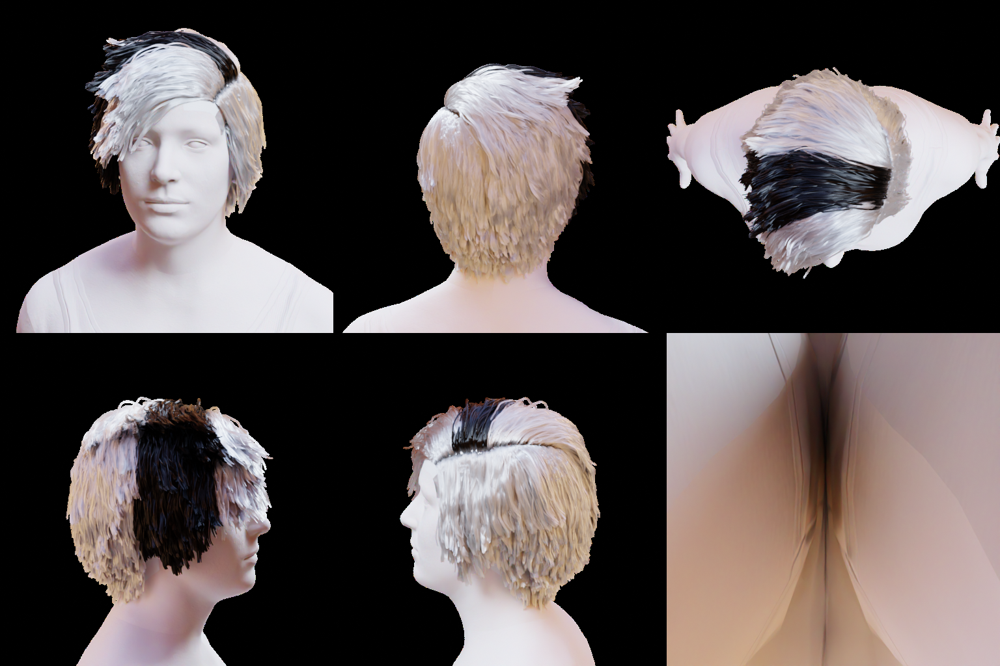

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
wrote ignore mask (100/99450 strands ignored) to /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2_trimmed/ignore_mask.npz
執行 Blender multi-view 渲染 (trimmed)...
00:00.320  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.135  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2_trimmed/front.png'
00:26.429  

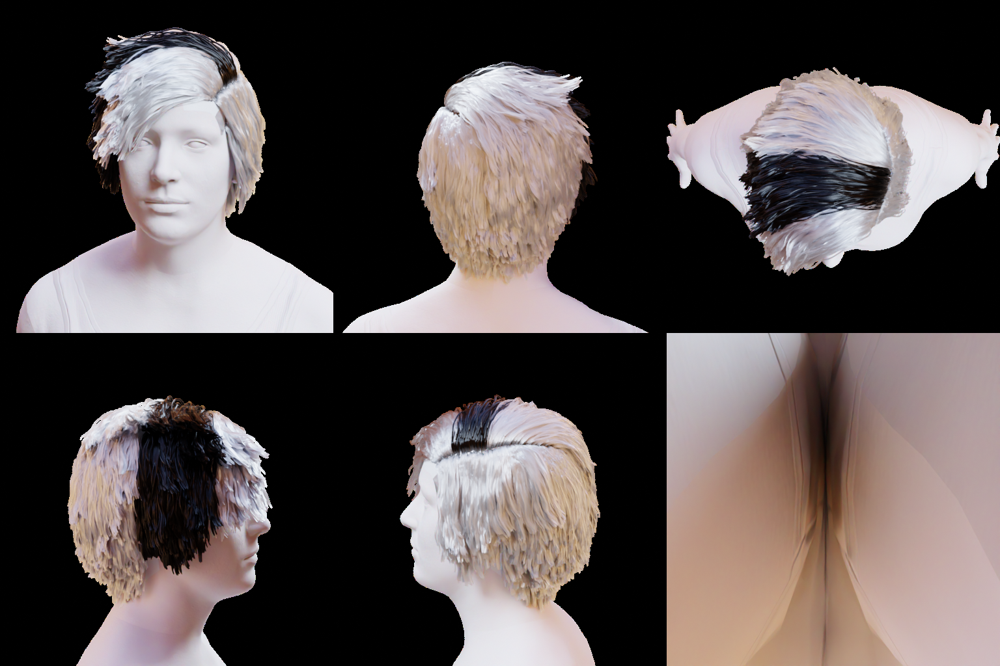

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2_trimmed/ignore_mask.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2_trimmed/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_2_trimmed/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
執行 Blender multi-view 渲染...
00:00.265  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.167  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3/front.png'
00:26.498  render           | Saved: '/home/kyh/Desktop/P76154

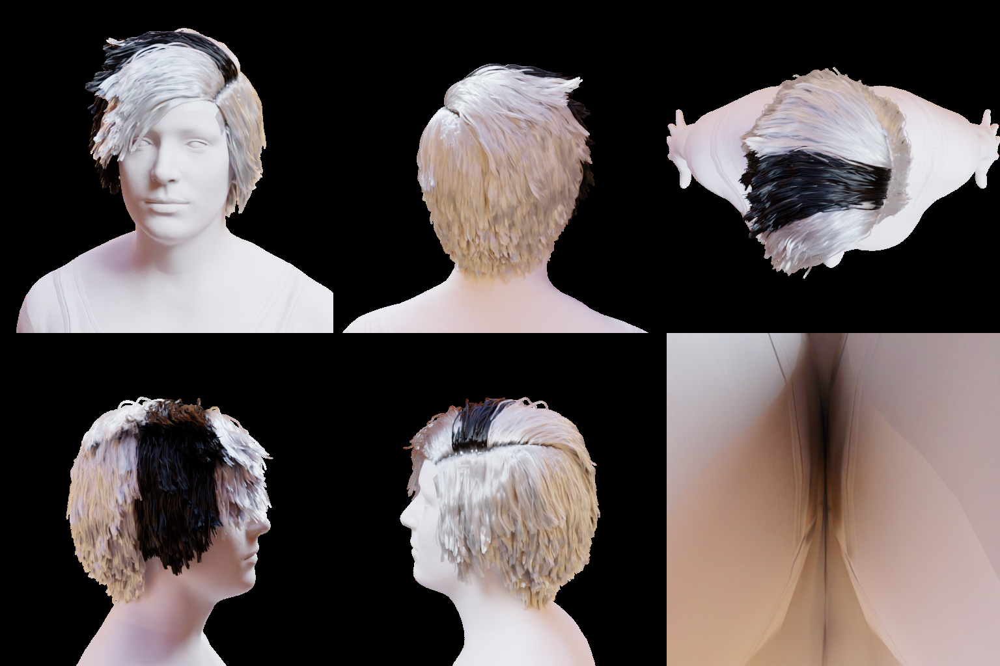

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3/scalp_grid_rgb.jpg
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/coloring_by_strand/median_templates_3D/template_notebook_color_matrix.npz
wrote ignore mask (100/99450 strands ignored) to /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3_trimmed/ignore_mask.npz
執行 Blender multi-view 渲染 (trimmed)...
00:00.320  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:15.186  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3_trimmed/front.png'
00:26.465  

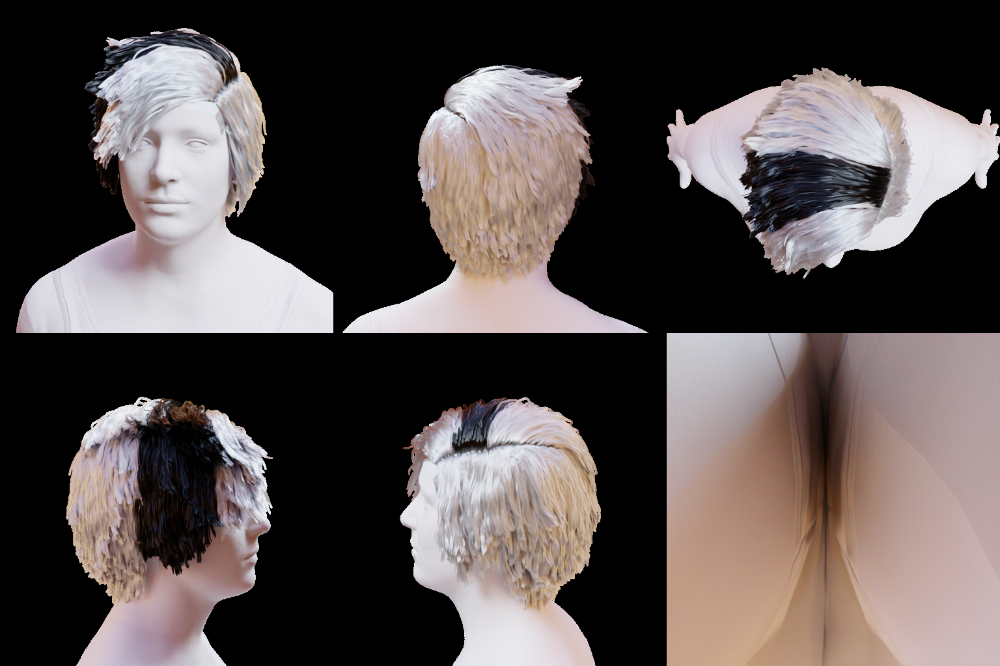

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3_trimmed/ignore_mask.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3_trimmed/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/scalp_grid_volume_sample/output/iter_3D_projection_3_trimmed/scalp_grid_rgb.jpg


In [ ]:
RUN_RENDER = True
 
if RUN_RENDER:
    render.render_iterations(
        iter_strand_masks, out_root=os.path.join(HERE, "output"),
        root_uv=root_uv, strands_npz=STRANDS_NPZ, dataset_path=DATASET_ROOT, grid_size=N,
        trim_masks=trimmed_masks, base_color=BASE_COLOR, highlight_color=HIGHLIGHT_COLOR,
        prefix="iter_3D_" if OVERLAP == "cell" else f"iter_3D_{OVERLAP}_",   # 兩種判定的輸出分開放
        source="mask_updating_test_3D.ipynb",
    )